# Step 6 — 2D Nonlinear Convection

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step06_nonlinear_convection_2d.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

We now replace the constant advection velocity with the solution itself, giving the 2D nonlinear convection (inviscid Burgers) system for the velocity $\mathbf{v} = (u, v)$.

**What you will learn:**

1. How nonlinear self-advection produces wave steepening in 2D
2. Working with two-component state vectors $(u, v)$
3. How the solution differs from the linear case

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} + v \frac{\partial u}{\partial y} = 0
$$

$$
\frac{\partial v}{\partial t} + u \frac{\partial v}{\partial x} + v \frac{\partial v}{\partial y} = 0
$$

or, in vector form, $\partial \mathbf{v} / \partial t + (\mathbf{v} \cdot \boldsymbol{\nabla}) \mathbf{v} = \mathbf{0}$.

In the linear case (Step 5) the wave translates at constant speed without changing shape. Here the local propagation speed *is* the solution: regions of higher amplitude travel faster, causing the wave front to steepen. Without viscosity, this eventually leads to a shock (gradient blow-up). In practice we run for a short time to observe the steepening before any numerical instability.

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ and $y$ are the spatial coordinates (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$, $y \in [0, L_y)$ | spatial coordinates | $\mathbb{R}$ |
| $t \in [t_0, t_1]$ | time | $\mathbb{R}$ |
| $\mathbf{v}(x, y, t) = (u, v)$ | velocity, with components $u$ along $x$ and $v$ along $y$ | $\mathbb{R}^2$ |
| $u_0(x, y)$, $v_0(x, y)$ | initial components, the same Gaussian bump with centre $(\mu_x, \mu_y)$ and width $\sigma_0$ | $\mathbb{R}$ |
| $L_x$, $L_y$ | domain lengths | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior grid cells along $x$ and $y$ | count |
| $\Delta x = L_x / N_{\Omega_x,x}$, $\Delta y = L_y / N_{\Omega_x,y}$, $\Delta t$ | grid spacings and time step | $\mathbb{R}_{>0}$ |
| $u_{j,i}$, $v_{j,i}$ | the components in the cell at row $j$ and column $i$; each array has $N_{\Omega_x,y} + 2$ rows and $N_{\Omega_x,x} + 2$ columns with the ghosts | $\mathbb{R}$ |
| $E(t)$ | kinetic energy | $\mathbb{R}_{\ge 0}$ |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |

## Grid layout and boundary conditions

In 2D, sesmax uses the **Arakawa C-grid** from finitevolX, where different variables live at different positions within each cell:

| Point | Location in cell $(i, j)$ | Holds |
| --- | --- | --- |
| T-points | cell centre | scalars |
| U-points | east and west faces, $i \pm \frac{1}{2}$ | fluxes in $x$ |
| V-points | north and south faces, $j \pm \frac{1}{2}$ | fluxes in $y$ |
| X-points | corners | vorticity (in some formulations) |

The full array has $N_{\Omega_x,y} + 2$ rows and $N_{\Omega_x,x} + 2$ columns, with a one-cell **ghost ring** on all sides around the $N_{\Omega_x,y} \times N_{\Omega_x,x}$ interior cells:

| Array axis | `0` | `1` … `N` | `N + 1` (or `-1`) |
| --- | --- | --- | --- |
| Rows (`N = N_{\Omega_x,y}`) | south ghost row | interior rows | north ghost row |
| Columns (`N = N_{\Omega_x,x}`) | west ghost column | interior columns | east ghost column |

The interior cells are `[1:-1, 1:-1]`. The ghost cells are filled by the boundary conditions before each evaluation of the right-hand side.

**Periodic BCs** (`enforce_periodic`) copy the last interior row or column into the opposite ghost row or column. Both $u$ and $v$ receive the same periodic treatment, shown here for a generic component $w \in \{u, v\}$:

- the south ghost row takes the north interior row, $w_{0,i} = w_{N_{\Omega_x,y},i}$
- the north ghost row takes the south interior row, $w_{N_{\Omega_x,y} + 1,i} = w_{1,i}$
- the west ghost column takes the east interior column, $w_{j,0} = w_{j,N_{\Omega_x,x}}$
- the east ghost column takes the west interior column, $w_{j,N_{\Omega_x,x} + 1} = w_{j,1}$

In [2]:
import diffrax as dfx
import einx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

`NonlinearConvection2D.create()` builds a model on a 2D Arakawa C-grid with `nx` by `ny` interior cells. The domain defaults to $L_x = L_y = 2$.

In [4]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells

num_cells_x = 64
num_cells_y = 64

# today (sesmax_core)
model = sxt.NonlinearConvection2D.create(nx=num_cells_x, ny=num_cells_y)

print(model)
print(f"Grid: Nx={model.grid.Nx}, Ny={model.grid.Ny}")
print(f"Spacing: dx={model.grid.dx:.4f}, dy={model.grid.dy:.4f}")

NonlinearConvection2D(
  grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125),
  advection=Advection2D(
    grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125),
    mask=None,
    recon=Reconstruction2D(
      grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125)
    ),
    _mask_hierarchy_x=None,
    _mask_hierarchy_y=None
  ),
  interp=Interpolation2D(
    grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125)
  ),
  diff=Difference2D(
    grid=CartesianGrid2D(Nx=66, Ny=66, Lx=2.0, Ly=2.0, dx=0.03125, dy=0.03125)
  ),
  mask=None
)
Grid: Nx=66, Ny=66
Spacing: dx=0.0312, dy=0.0312


## 2. Initial condition

A 2D Gaussian bump with centre $(\mu_x, \mu_y) = (1, 1)$ and width $\sigma_0 = 0.2$ for both velocity components:

$$
u_0(x, y) = v_0(x, y) = \exp\left(-\frac{(x - \mu_x)^2 + (y - \mu_y)^2}{2 \sigma_0^2}\right)
$$

In [5]:
# Shapes: N_Ωx,x + 2 = 66 columns and N_Ωx,y + 2 = 66 rows with the ghosts;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

centre_x = 1.0
centre_y = 1.0
bump_width = 0.2
inner = slice(1, -1)
interior = (inner, inner)

# xᵢ = i Δx
x_position = jnp.arange(model.grid.Nx) * model.grid.dx  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_position = jnp.arange(model.grid.Ny) * model.grid.dy  # → (N_Ωx,y + 2,)
# (xᵢ, yⱼ) on every cell
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# zₓ = (x − μₓ) / σ₀
standardised_x = (x_grid - centre_x) / bump_width  # → G
# z_y = (y − μ_y) / σ₀
standardised_y = (y_grid - centre_y) / bump_width  # → G
# u₀(x, y) = exp(−(zₓ² + z_y²) / 2)
radius_squared = standardised_x**2 + standardised_y**2  # → G
initial_u = jnp.exp(-0.5 * radius_squared)  # → G
# v₀(x, y) = u₀(x, y)
initial_v = initial_u  # → G

# today (sesmax_core)
initial_state = sxt.NonlinearConvection2DState(u=initial_u, v=initial_v)

print(f"State shapes: u={initial_state.u.shape}, v={initial_state.v.shape}")

State shapes: u=(66, 66), v=(66, 66)


## 3. Run the simulation

We integrate from $t_0 = 0$ to $t_1 = 0.3$ and save a snapshot every time step.

In [6]:
# Shapes: N_T = 150 saved snapshots; N_Ωx,y + 2 = 66 rows and N_Ωx,x + 2 = 66 columns;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

time_step = 0.002
start_time = 0.0
end_time = 0.3

# tₖ = t₀ + k Δt
save_times = jnp.arange(start_time, end_time, time_step)  # → (N_T,)

# today (sesmax_core, diffrax)
# (u, v)(x, y, tₖ) for each saved time
solution = model.integrate(  # u, v → N_T × G
    initial_state,
    t0=start_time,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)

print(f"Solution shapes: u={solution.ys.u.shape}, v={solution.ys.v.shape}")

Solution shapes: u=(150, 66, 66), v=(150, 66, 66)


## 4. Visualize steepening

Compare the initial and final $u$ and $v$ fields. The Gaussian should steepen on one side as faster-moving peaks overtake slower regions.

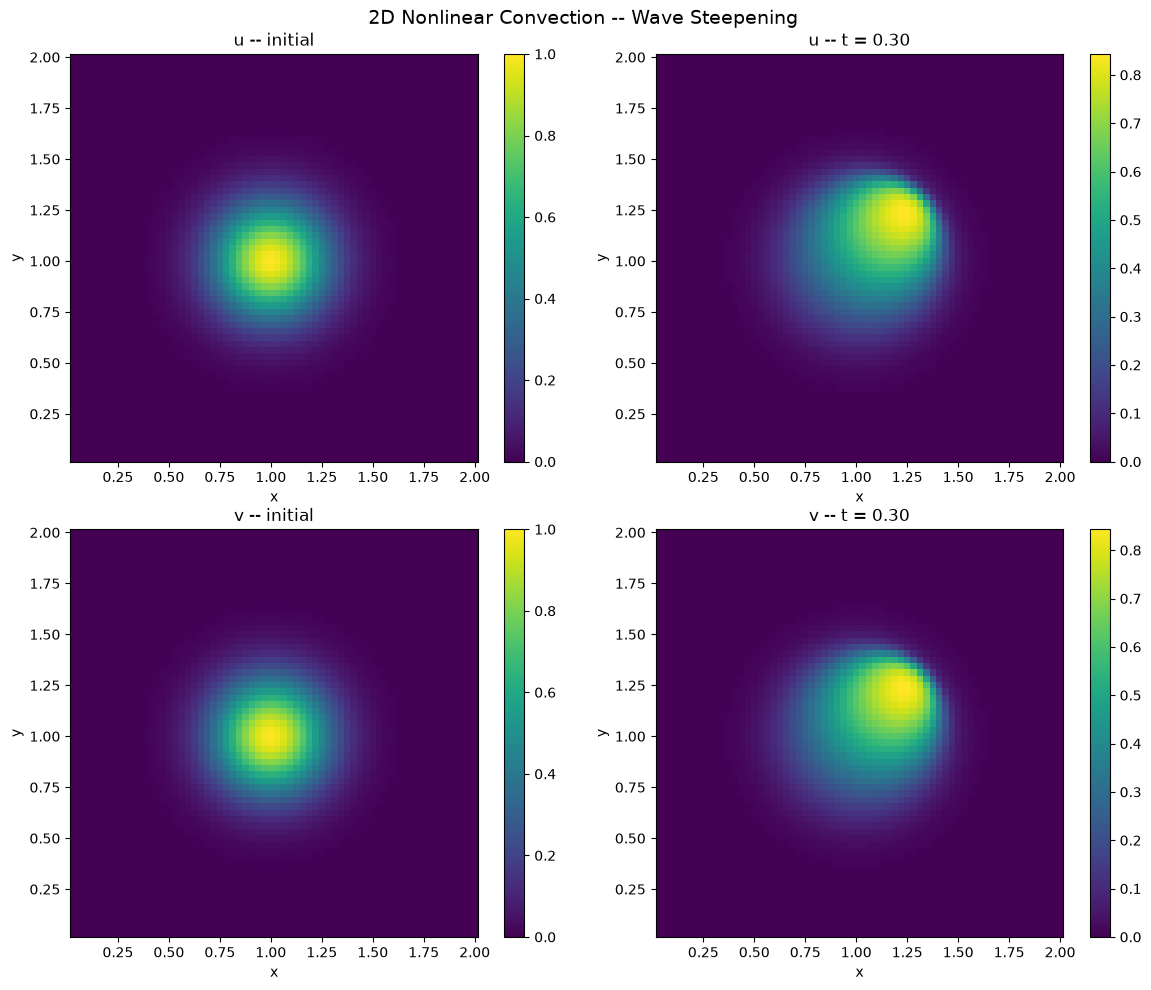

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

fields = [
    (solution.ys.u[0], "u -- initial"),
    (solution.ys.u[-1], f"u -- t = {float(save_times[-1]):.2f}"),
    (solution.ys.v[0], "v -- initial"),
    (solution.ys.v[-1], f"v -- t = {float(save_times[-1]):.2f}"),
]

for ax, (field, title) in zip(axes.flat, fields, strict=True):
    pcm = ax.pcolormesh(
        x_grid[interior],
        y_grid[interior],
        field[interior],
        shading="auto",
        cmap="viridis",
    )
    plt.colorbar(pcm, ax=ax)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)
    ax.set_aspect("equal")

plt.suptitle("2D Nonlinear Convection -- Wave Steepening", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Cross-sections through the steepening front

Taking a 1D slice through the middle row (for $u$) and the middle column (for $v$) makes the steepening easier to see.

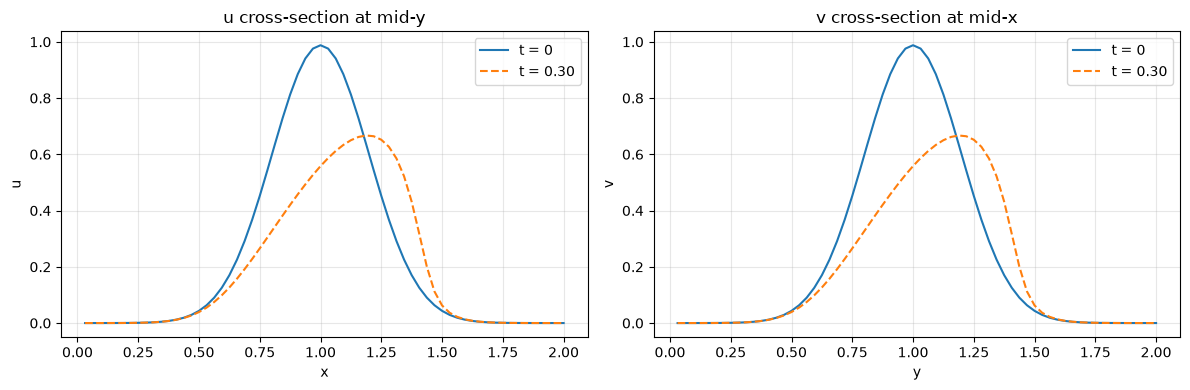

In [8]:
# Shapes: N_T = 150 saved snapshots; N_Ωx,y + 2 = 66 rows and N_Ωx,x + 2 = 66 columns

mid_row = model.grid.Ny // 2
mid_column = model.grid.Nx // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# u cross-section
axes[0].plot(x_position[inner], solution.ys.u[0, mid_row, inner], label="t = 0", lw=1.5)
axes[0].plot(
    x_position[inner],
    solution.ys.u[-1, mid_row, inner],
    label=f"t = {float(save_times[-1]):.2f}",
    lw=1.5,
    ls="--",
)
axes[0].set_xlabel("x")
axes[0].set_ylabel("u")
axes[0].set_title("u cross-section at mid-y")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# v cross-section
axes[1].plot(
    y_position[inner], solution.ys.v[0, inner, mid_column], label="t = 0", lw=1.5
)
axes[1].plot(
    y_position[inner],
    solution.ys.v[-1, inner, mid_column],
    label=f"t = {float(save_times[-1]):.2f}",
    lw=1.5,
    ls="--",
)
axes[1].set_xlabel("y")
axes[1].set_ylabel("v")
axes[1].set_title("v cross-section at mid-x")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Compare with linear convection

In the linear case (Step 5) the peak amplitude is preserved. Here self-advection redistributes energy and the peak drops as the front steepens.

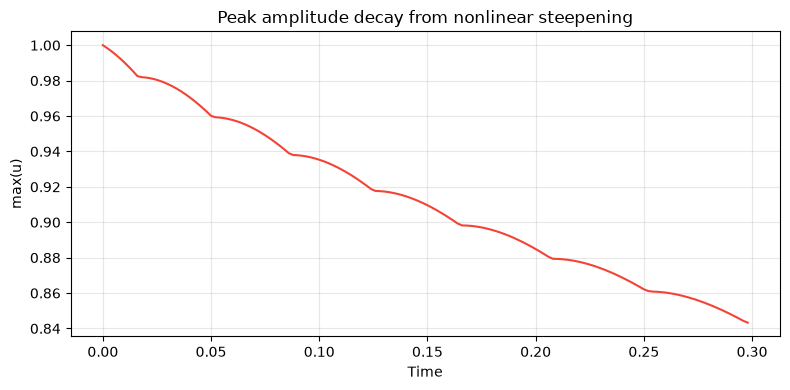

In [9]:
# Shapes: N_T = 150 saved snapshots; N_Ωx,y = 64 rows and N_Ωx,x = 64 columns interior

# Uₖ = maxⱼ,ᵢ uⱼ,ᵢ(tₖ)
interior_u = solution.ys.u[:, *interior]  # → N_T × N_Ωx,y × N_Ωx,x
peak_u = einx.max("t [y x] -> t", interior_u)  # → (N_T,)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(save_times, peak_u, lw=1.5, color="#F44336")
ax.set_xlabel("Time")
ax.set_ylabel("max(u)")
ax.set_title("Peak amplitude decay from nonlinear steepening")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Energy evolution

The total kinetic energy,

$$
E(t) = \frac{1}{2} \int_0^{L_y} \int_0^{L_x} \left(u^2 + v^2\right) \mathrm{d}x \mathrm{d}y \approx \frac{\Delta x \Delta y}{2} \sum_{j=1}^{N_{\Omega_x,y}} \sum_{i=1}^{N_{\Omega_x,x}} \left(u_{j,i}^2 + v_{j,i}^2\right)
$$

is not conserved here, even before a shock forms. Unlike the incompressible flows of steps 12 and 13, this velocity field is not divergence-free, and for a smooth periodic solution the energy changes at the rate

$$
\frac{\mathrm{d}E}{\mathrm{d}t} = \frac{1}{2} \int_0^{L_y} \int_0^{L_x} \left(u^2 + v^2\right) \nabla \cdot \mathbf{v} \mathrm{d}x \mathrm{d}y
$$

On top of that, the upwind scheme's numerical dissipation removes energy, most strongly where the front steepens.

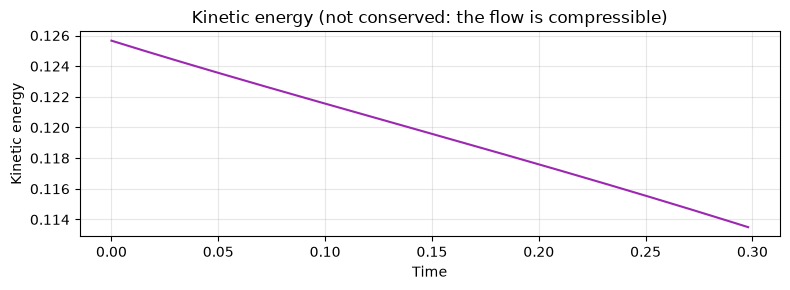

Energy: initial = 0.125664, final = 0.113498


In [10]:
# Shapes: N_T = 150 saved snapshots; N_Ωx,y = 64 rows and N_Ωx,x = 64 columns interior

x_spacing = float(model.grid.dx)
y_spacing = float(model.grid.dy)

# uⱼ,ᵢ(tₖ) and vⱼ,ᵢ(tₖ) without ghosts
interior_v = solution.ys.v[:, *interior]  # → N_T × N_Ωx,y × N_Ωx,x
# uⱼ,ᵢ² + vⱼ,ᵢ²
speed_squared = interior_u**2 + interior_v**2  # → N_T × N_Ωx,y × N_Ωx,x
# Σⱼ Σᵢ (uⱼ,ᵢ² + vⱼ,ᵢ²)
total_speed_squared = einx.sum("t [y x] -> t", speed_squared)  # → (N_T,)
# E(tₖ) = (Δx Δy / 2) Σⱼ Σᵢ (uⱼ,ᵢ² + vⱼ,ᵢ²)
half_sum = 0.5 * total_speed_squared  # → (N_T,)
energy = half_sum * x_spacing * y_spacing  # → (N_T,)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(save_times, energy, lw=1.5, color="#9C27B0")
ax.set_xlabel("Time")
ax.set_ylabel("Kinetic energy")
ax.set_title("Kinetic energy (not conserved: the flow is compressible)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Energy: initial = {float(energy[0]):.6f}, final = {float(energy[-1]):.6f}")

## 8. Gradient through the initial state

Even without explicit parameters, we can differentiate through the nonlinear dynamics with respect to the initial condition. The loss is the sum of squares of both components at $t_1 = 0.1$ over every cell, including the ghosts,

$$
\mathcal{L}(u_0, v_0) = \sum_{j=0}^{N_{\Omega_x,y} + 1} \sum_{i=0}^{N_{\Omega_x,x} + 1} \left(u_{j,i}(t_1)^2 + v_{j,i}(t_1)^2\right)
$$

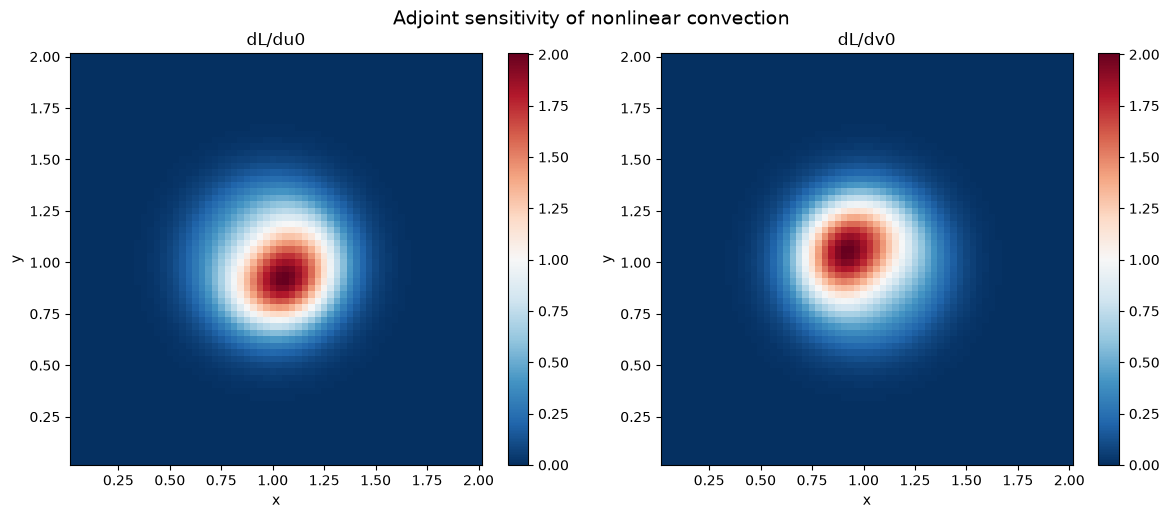

In [11]:
# Shapes: N_Ωx,y + 2 = 66 rows and N_Ωx,x + 2 = 66 columns with the ghosts;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts


def state_loss(state):
    # today (sesmax_core, diffrax)
    # (u, v)(x, y, t₁; u₀, v₀)
    final_solution = model.integrate(state, t0=0.0, t1=0.1, dt=0.002)
    # uⱼ,ᵢ² + vⱼ,ᵢ²
    speed_squared = final_solution.ys.u**2 + final_solution.ys.v**2
    # ℒ(u₀, v₀) = Σⱼ Σᵢ (uⱼ,ᵢ(t₁)² + vⱼ,ᵢ(t₁)²)
    loss = jnp.sum(speed_squared)  # → ()
    return loss


# (∂ℒ/∂u₀, ∂ℒ/∂v₀)
state_grads = jax.grad(state_loss)(initial_state)  # u, v → G

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pcm0 = axes[0].pcolormesh(
    x_grid[interior],
    y_grid[interior],
    state_grads.u[interior],
    shading="auto",
    cmap="RdBu_r",
)
plt.colorbar(pcm0, ax=axes[0])
axes[0].set_title("dL/du0")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_aspect("equal")

pcm1 = axes[1].pcolormesh(
    x_grid[interior],
    y_grid[interior],
    state_grads.v[interior],
    shading="auto",
    cmap="RdBu_r",
)
plt.colorbar(pcm1, ax=axes[1])
axes[1].set_title("dL/dv0")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_aspect("equal")

plt.suptitle("Adjoint sensitivity of nonlinear convection", fontsize=14)
plt.tight_layout()
plt.show()

## Summary

| Concept | API |
| --- | --- |
| Create model | `NonlinearConvection2D.create(nx=64, ny=64)` |
| Two-component state | `NonlinearConvection2DState(u=initial_u, v=initial_v)` |
| Self-advection | velocity = solution itself |
| Observable effect | wave steepening, peak decay |

**Next:** Step 7 adds diffusion in 2D, which counteracts steepening and has an analytical Gaussian solution we can validate against.